# Notebook content: Retrieved data 

## Chronological Overview

In [1]:
# importing relevant start libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# readable table of column descriptions for master_lst_cell.csv
col_desc = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/Merged/columns.csv')
col_desc = col_desc[col_desc['table'] == 'master_lst_cell.csv'][['variable', 'description']].reset_index(drop=True)

pd.set_option('display.max_colwidth', None)  # show the full description, no truncation
pd.set_option('display.width', 200)
col_desc


,variable,description
0,lst_cell_id,Id of the LST cell (same as lst_cell_id in master_10m.csv)
1,lst_cell_lon,Longitude of the LST cell centre (WGS84)
2,lst_cell_lat,Latitude of the LST cell centre (WGS84)
3,n_pixels_10m,Number of 10 m pixels of the area inside this LST cell (cells on the boundary are partly outside)
4,lst_downscaled_K,"CLIM4cities land surface temperature (sen3_downscaled), Kelvin, 13 June 2023 09:25 UTC (one value per cell)"
5,lst_downscaled_C,"Same as lst_downscaled_K, in degrees Celsius (one value per cell)"
6,lst_interpolated_K,"CLIM4cities land surface temperature (interpolated), Kelvin, 13 June 2023 09:25 UTC (one value per cell)"
7,ndvi_mean,Mean NDVI over the cell's 10 m pixels that have a value
8,fvc_mean,Mean fractional vegetation cover over the cell's 10 m pixels that have a value
9,imd_2021_pct_mean,Mean imperviousness 2021 (%) over the cell's 10 m pixels that have a value


In [3]:
df_master = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/Merged/master_lst_cell.csv')
df_master.head(10)

,lst_cell_id,lst_cell_lon,lst_cell_lat,n_pixels_10m,lst_downscaled_K,lst_downscaled_C,lst_interpolated_K,ndvi_mean,fvc_mean,imd_2021_pct_mean,...,tcd_2023_pct_mean,elevation_m_mean,slope_deg_mean,share_wc_tree,share_wc_grass,share_wc_built,share_wc_water,share_ua_street_tree,share_building,bbh_mean_where_built_m
0,36,12.564703,55.734206,4,307.29,34.14,306.51,NaN,NaN,81.7500,...,NaN,9.6325,1.4275,0.0000,0.0000,1.0000,0.0,0.7500,0.0000,NaN
1,111,12.564703,55.731022,458,307.98,34.83,306.55,0.4172,0.2452,64.4039,...,0.0000,11.9115,1.6764,0.2664,0.0044,0.7293,0.0,0.0742,0.4782,7.42
2,112,12.567886,55.731022,369,307.14,33.99,306.03,0.2949,0.1875,73.9268,...,3.7049,10.4985,1.4276,0.2276,0.0054,0.7669,0.0,0.1734,0.2791,6.10
3,113,12.571070,55.731022,58,305.18,32.03,305.51,0.6712,0.6191,25.2759,...,9.2931,12.1776,1.3516,1.0000,0.0000,0.0000,0.0,0.4310,0.6897,7.58
4,171,12.516944,55.727839,17,307.10,33.95,305.66,0.8294,0.9226,0.0000,...,0.0000,20.7324,1.5435,1.0000,0.0000,0.0000,0.0,0.7059,0.0000,NaN
5,172,12.520128,55.727839,298,306.41,33.26,305.84,0.8856,0.9881,0.0000,...,29.1007,21.3975,3.6000,0.9597,0.0268,0.0134,0.0,0.8658,0.0000,NaN
6,173,12.523312,55.727839,299,307.19,34.04,306.04,0.7270,0.7483,20.0602,...,58.6388,22.4417,2.8922,0.7492,0.0334,0.2174,0.0,0.6957,0.1505,7.09
7,174,12.526496,55.727839,167,307.13,33.98,306.21,0.4766,0.3874,49.5150,...,18.1976,21.1056,1.2720,0.5749,0.0000,0.4251,0.0,0.3533,0.2874,7.06
8,175,12.529680,55.727839,184,306.32,33.17,306.33,0.5905,0.4761,31.9565,...,6.6685,18.8255,1.0042,0.9076,0.0109,0.0815,0.0,0.1467,0.4076,6.20
9,176,12.532864,55.727839,172,305.70,32.55,306.36,0.5359,0.4597,12.4942,...,15.5872,17.7183,2.5448,0.4942,0.1628,0.3430,0.0,0.3430,0.0930,6.25


## Exploratory Data Analysis (EDA) of df_master

**Why EDA before modelling?** Cox (2017) describes EDA as finding out *what data we have*, *what trends are present*, and therefore *which analyses are appropriate*. Tukey (1977) describes it as detective work: we look at the data before we test anything.

The data are geospatial. Each row is a cell of the CLIM4cities LST grid, roughly 200 × 355 m, identified by its coordinates (`lst_cell_lon`, `lst_cell_lat`). The row unit is set by the LST grid, not by the underlying data: LST only exists at that resolution, so we aggregated the 10 m pixels up to it, and the table is at LST resolution because the target is. We therefore look at both the distributions of the variables and how the values are arranged in space.

**Business question:** Which features of the urban surface are associated with higher land surface temperature (LST) in Copenhagen on 13 June 2023 at 11:25 Danish time (09:25 UTC)?

The steps are: 1) what data do we have, 2) describe, 3) distributions, 4) outliers, 5) map, 6) relationships, 7) a hypothesis test, 8) interpretation.

### 1. What data do we have?

First we check the size, data types and missing values. Following Stevens (1946) and Cox (2017), variables are either **quantitative** (continuous or discrete) or **qualitative** (nominal or ordinal). `lst_cell_id` is an identifier. It is stored as a number, but averaging it would be meaningless.

Missing values matter here. The 510 cells without an LST value are not missing at random: they lie along water and the coast, which we need to keep in mind for the rest of the analysis.

In [4]:
print('Rows and columns:', df_master.shape)
print()
print(df_master.dtypes)

Rows and columns: (1671, 21)

lst_cell_id                 int64
lst_cell_lon              float64
lst_cell_lat              float64
n_pixels_10m                int64
lst_downscaled_K          float64
lst_downscaled_C          float64
lst_interpolated_K        float64
ndvi_mean                 float64
fvc_mean                  float64
imd_2021_pct_mean         float64
imd_2024_pct_mean         float64
tcd_2023_pct_mean         float64
elevation_m_mean          float64
slope_deg_mean            float64
share_wc_tree             float64
share_wc_grass            float64
share_wc_built            float64
share_wc_water            float64
share_ua_street_tree      float64
share_building            float64
bbh_mean_where_built_m    float64
dtype: object


In [5]:
# missing values per column, only columns with at least one missing value
missing = df_master.isna().sum()
missing[missing > 0].sort_values(ascending=False)

lst_downscaled_K          510
lst_downscaled_C          510
lst_interpolated_K        510
bbh_mean_where_built_m    324
fvc_mean                   67
imd_2021_pct_mean          42
imd_2024_pct_mean          42
ndvi_mean                   6
tcd_2023_pct_mean           1
dtype: int64

### 2. Describe

Descriptive statistics give a quick overview of the mean, median, spread and skewness. We read the mean and the median together: if they are far apart, the distribution is skewed and the mean alone is misleading. A negative skewness means the tail points towards low values. For a skewed variable, the mean says little on its own (Cox, 2017).

In [6]:
key_cols = ['lst_downscaled_C', 'ndvi_mean', 'fvc_mean', 'imd_2024_pct_mean', 'tcd_2023_pct_mean',
            'elevation_m_mean', 'slope_deg_mean', 'share_wc_built', 'share_building', 'bbh_mean_where_built_m']

desc = df_master[key_cols].describe().T
desc['skew'] = df_master[key_cols].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
lst_downscaled_C,1161.0,33.67,2.07,26.48,32.54,34.13,35.19,37.68,-0.93
ndvi_mean,1665.0,0.38,0.20,-0.51,0.24,0.39,0.51,0.90,-0.06
fvc_mean,1604.0,0.29,0.22,0.00,0.12,0.26,0.40,0.99,0.92
imd_2024_pct_mean,1629.0,50.17,30.89,0.00,24.29,52.42,77.43,100.00,-0.19
tcd_2023_pct_mean,1670.0,6.87,13.46,0.00,0.00,0.49,6.91,92.91,2.83
elevation_m_mean,1671.0,9.07,7.66,-4.96,2.90,7.02,13.73,36.22,0.95
slope_deg_mean,1671.0,2.16,1.24,0.00,1.29,2.00,2.83,9.24,1.07
share_wc_built,1671.0,0.51,0.33,0.00,0.18,0.58,0.81,1.00,-0.25
share_building,1671.0,0.30,0.23,0.00,0.04,0.32,0.49,0.83,0.05
bbh_mean_where_built_m,1347.0,9.28,4.23,3.00,6.06,8.39,11.54,40.77,1.61


### 3. Distribution of the target (LST)

LST is the variable we want to predict, so its distribution matters most.
- The **histogram** shows how many cells fall into each temperature interval.
- The **boxplot** shows the median, the quartiles and potential outliers.
- The **Q-Q plot** compares the data with a normal distribution. If the points follow the line, the data are approximately normal.

The result decides whether we can use means and parametric tests later, or whether we should use medians and rank-based tests (Cox, 2017). We use only the 1,161 cells that have an LST value.

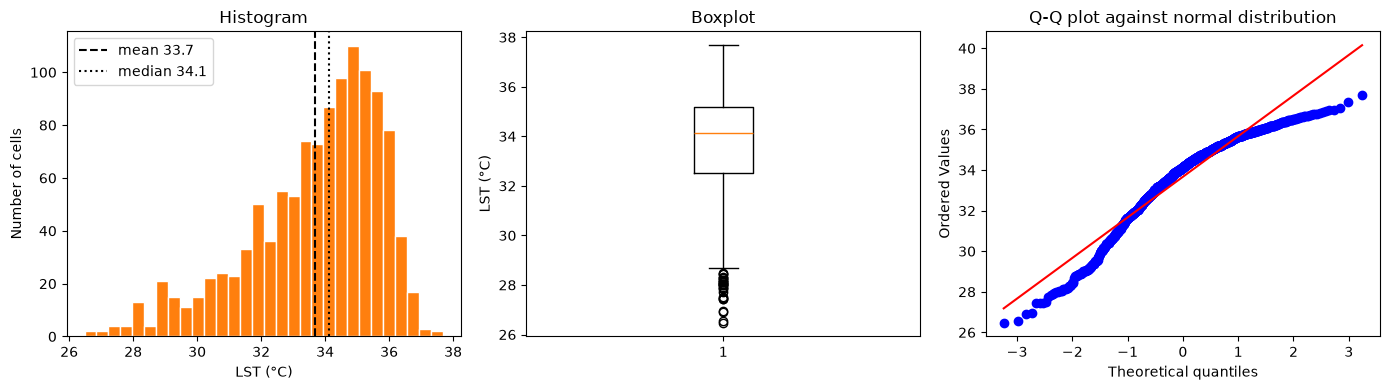

In [7]:
from scipy import stats

lst = df_master['lst_downscaled_C'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(lst, bins=30, color='tab:orange', edgecolor='white')
axes[0].axvline(lst.mean(), color='k', linestyle='--', label=f'mean {lst.mean():.1f}')
axes[0].axvline(lst.median(), color='k', linestyle=':', label=f'median {lst.median():.1f}')
axes[0].set_xlabel('LST (°C)')
axes[0].set_ylabel('Number of cells')
axes[0].set_title('Histogram')
axes[0].legend()

axes[1].boxplot(lst)
axes[1].set_ylabel('LST (°C)')
axes[1].set_title('Boxplot')

stats.probplot(lst, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q plot against normal distribution')

plt.tight_layout()
plt.show()

### 4. Outliers

We use the IQR rule: values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR are flagged as outliers. An outlier is not automatically an error. In geospatial data we therefore check *where* the outliers are:
- If they cluster in one place, for example a large car park or an industrial area, they probably reflect a real physical feature.
- If they are scattered, they may indicate a measurement or processing error.

In [8]:
q1, q3 = lst.quantile(0.25), lst.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

with_lst = df_master.dropna(subset=['lst_downscaled_C'])
outliers = with_lst[(with_lst['lst_downscaled_C'] < lower) | (with_lst['lst_downscaled_C'] > upper)]

print(f'Bounds: {lower:.2f} °C to {upper:.2f} °C')
print(f'Number of outliers: {len(outliers)}')
outliers[['lst_cell_lon', 'lst_cell_lat', 'lst_downscaled_C', 'imd_2024_pct_mean', 'share_wc_built']].sort_values('lst_downscaled_C')

Bounds: 28.57 °C to 39.16 °C
Number of outliers: 28


,lst_cell_lon,lst_cell_lat,lst_downscaled_C,imd_2024_pct_mean,share_wc_built
1648,12.529680,55.616403,26.48,0.0000,0.0000
1580,12.545599,55.625954,26.55,0.0000,0.0000
1579,12.542415,55.625954,26.91,0.0000,0.0000
1645,12.520128,55.616403,26.93,7.9986,0.0872
1581,12.548783,55.625954,27.45,0.0000,0.0000
1669,12.520128,55.613219,27.45,35.5462,0.5798
1245,12.577438,55.654609,27.46,0.0000,0.0000
1649,12.532864,55.616403,27.52,0.0000,0.0000
1244,12.574254,55.654609,27.72,0.1042,0.0000
177,12.504209,55.715103,27.84,3.3376,0.0383


### 5. Map the data

The data have coordinates, so a map is the most natural view. Bertin (1967) argues that position is the visual variable we read most accurately. We therefore plot each cell at its longitude and latitude and colour it by temperature.

Two choices:
- **Colour scale:** LST is quantitative, so we use a sequential colour map (`inferno`), where low and high temperatures follow a natural order. A rainbow scale has no clear order and is harder to read.
- **Geospatial pitfall:** One degree of longitude is shorter than one degree of latitude at 55.7° N. Without correction, the map is stretched east–west, which distorts the spatial pattern. We correct the aspect ratio with `aspect = 1 / cos(latitude)`.

The grey cells are those without LST. If they cluster along the coast, that confirms what we found in step 1.

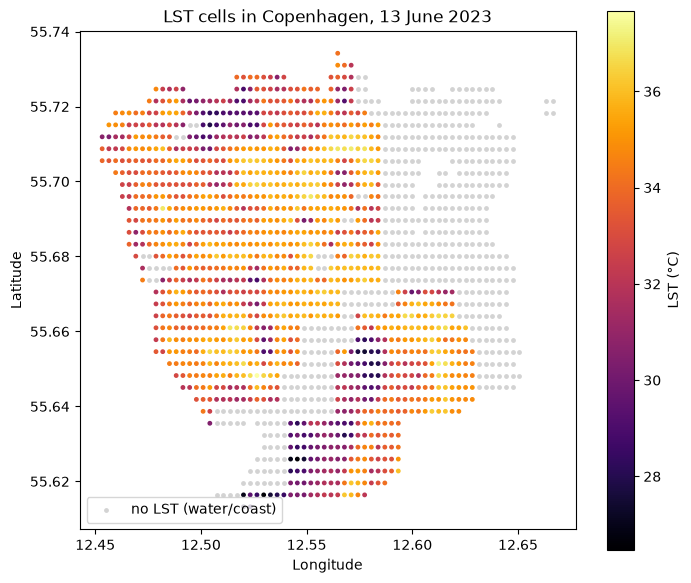

In [9]:
mid_lat = df_master['lst_cell_lat'].mean()

fig, ax = plt.subplots(figsize=(8, 7))

no_lst = df_master[df_master['lst_downscaled_C'].isna()]
ax.scatter(no_lst['lst_cell_lon'], no_lst['lst_cell_lat'], s=6, color='lightgrey', label='no LST (water/coast)')

sc = ax.scatter(df_master['lst_cell_lon'], df_master['lst_cell_lat'],
                c=df_master['lst_downscaled_C'], cmap='inferno', s=6)
plt.colorbar(sc, ax=ax, label='LST (°C)')

ax.set_aspect(1 / np.cos(np.radians(mid_lat)))
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('LST cells in Copenhagen, 13 June 2023')
ax.legend(loc='lower left')
plt.show()

### 5b. Grid view with values

The scatter map shows the spatial pattern, but not the numbers. Here each LST cell is placed on its regular grid position and its value is printed in the cell, so individual values can be read directly. Each cell is about 200 m wide and 355 m high, so the aspect ratio is set from the cell size. Grey positions have no LST value: they are water/coast, or outside the data area.

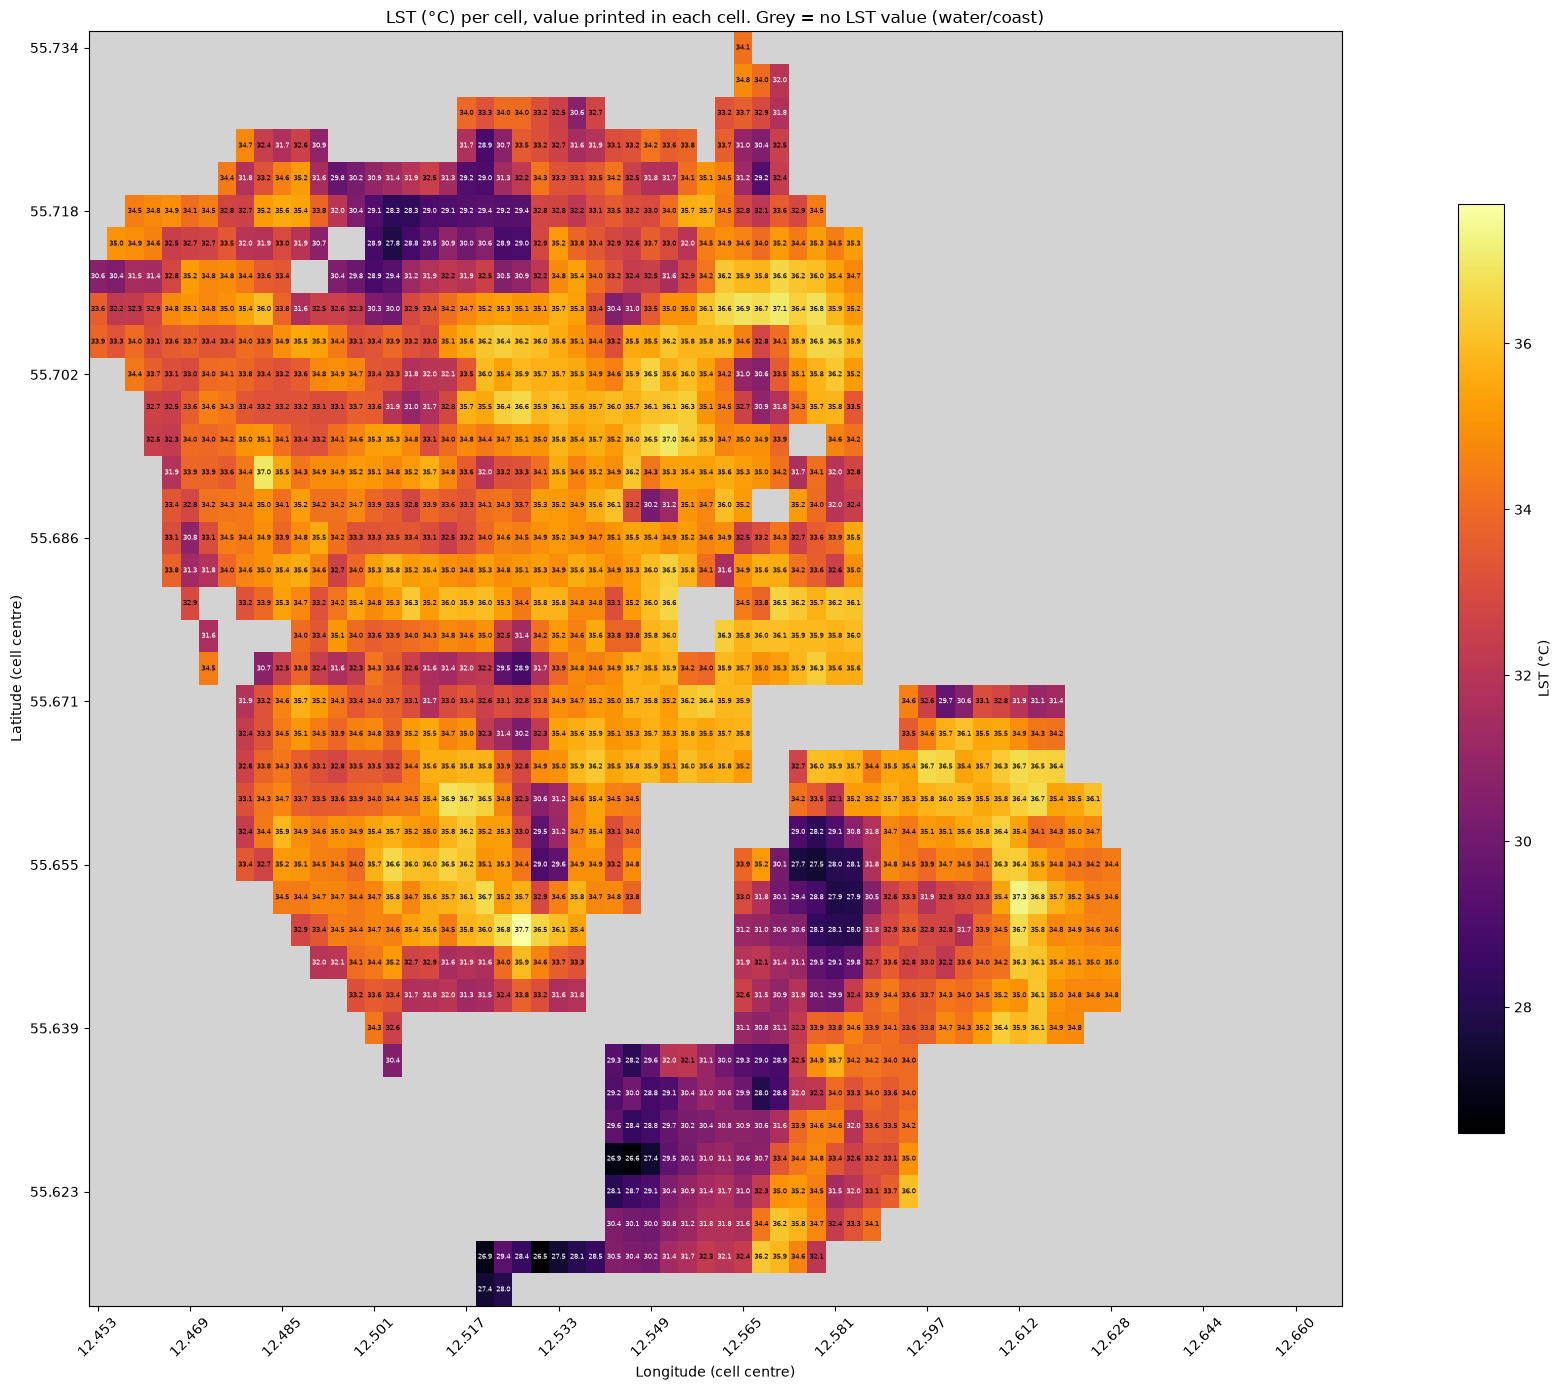

In [10]:
# place each LST cell on a regular grid: column from longitude, row from latitude
dlon = np.diff(np.sort(df_master['lst_cell_lon'].unique())).min()
dlat = np.diff(np.sort(df_master['lst_cell_lat'].unique())).min()
grid_cells = df_master.assign(
    col=np.round((df_master['lst_cell_lon'] - df_master['lst_cell_lon'].min()) / dlon).astype(int),
    row=np.round((df_master['lst_cell_lat'] - df_master['lst_cell_lat'].min()) / dlat).astype(int),
)
grid = grid_cells.pivot(index='row', columns='col', values='lst_downscaled_C')
# keep empty grid columns and rows so the spacing is correct
grid = grid.reindex(index=range(grid_cells['row'].max() + 1), columns=range(grid_cells['col'].max() + 1))
grid = grid.sort_index(ascending=False)

# cells are about 200 m wide and 355 m high, so the aspect ratio is set from the cell size
mid_lat = df_master['lst_cell_lat'].mean()
cell_aspect = dlat / (dlon * np.cos(np.radians(mid_lat)))

fig, ax = plt.subplots(figsize=(24, 14))
ax.set_facecolor('lightgrey')  # grey background = grid position with no LST value
im = ax.imshow(grid.values, cmap='inferno', aspect=cell_aspect)

# print the LST value in every cell that has one
for (r, c), value in np.ndenumerate(grid.values):
    if not np.isnan(value):
        color = 'white' if im.norm(value) < 0.5 else 'black'
        ax.text(c, r, f'{value:.1f}', ha='center', va='center', fontsize=5, color=color)

# label every 5th column and row with its coordinate
col_ticks = np.arange(0, grid.shape[1], 5)
row_ticks = np.arange(0, grid.shape[0], 5)
ax.set_xticks(col_ticks)
ax.set_xticklabels([f'{df_master["lst_cell_lon"].min() + c * dlon:.3f}' for c in col_ticks], rotation=45)
ax.set_yticks(row_ticks)
ax.set_yticklabels([f'{df_master["lst_cell_lat"].min() + (grid.shape[0] - 1 - r) * dlat:.3f}' for r in row_ticks])
ax.set_xlabel('Longitude (cell centre)')
ax.set_ylabel('Latitude (cell centre)')
ax.set_title('LST (°C) per cell, value printed in each cell. Grey = no LST value (water/coast)')
plt.colorbar(im, ax=ax, label='LST (°C)', fraction=0.02)
plt.tight_layout()
plt.show()

### 6. Relationships

We examine how each candidate explanatory variable relates to LST.

- **Correlation (r)** measures only linear association and says nothing about causation.
- **Anscombe's quartet** shows that four datasets can have the same r and very different patterns. This is why we always plot scatterplots alongside correlation coefficients.
- **Correlation between explanatory variables:** if two variables are almost identical, for example imperviousness in 2021 and 2024, one adds little new information. This can make a later model unstable.

In [11]:
d = df_master.dropna(subset=['lst_downscaled_C'])
cols = ['ndvi_mean', 'fvc_mean', 'imd_2024_pct_mean', 'tcd_2023_pct_mean', 'elevation_m_mean',
        'slope_deg_mean', 'share_wc_built', 'share_building']

# correlation with LST, sorted
print(d[['lst_downscaled_C'] + cols].corr()['lst_downscaled_C'].round(2).sort_values())

fvc_mean            -0.77
ndvi_mean           -0.73
tcd_2023_pct_mean   -0.60
elevation_m_mean     0.08
slope_deg_mean       0.11
share_building       0.77
imd_2024_pct_mean    0.83
share_wc_built       0.84
lst_downscaled_C     1.00
Name: lst_downscaled_C, dtype: float64


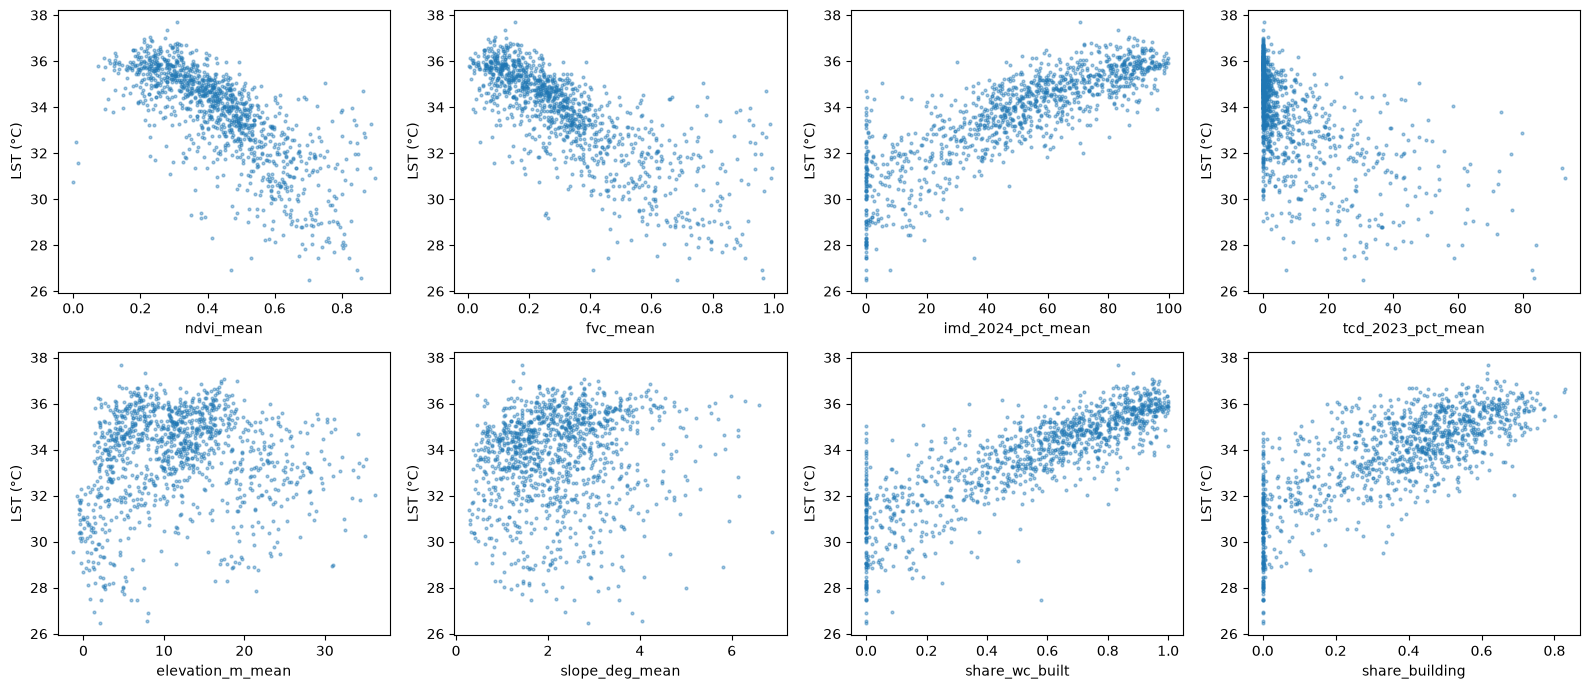

In [12]:
# scatterplot of each variable against LST
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    ax.scatter(d[col], d['lst_downscaled_C'], s=4, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('LST (°C)')
plt.tight_layout()
plt.show()

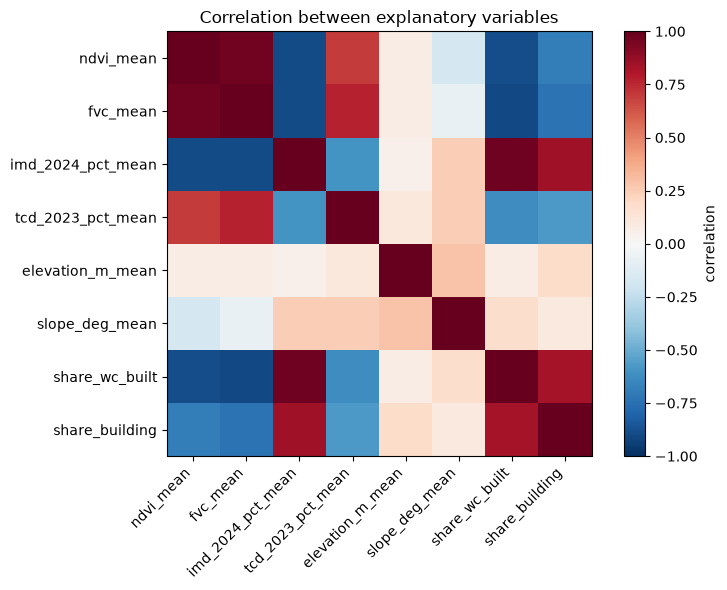

In [13]:
# correlation between the explanatory variables
corr = d[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
plt.colorbar(im, ax=ax, label='correlation')
ax.set_title('Correlation between explanatory variables')
plt.tight_layout()
plt.show()

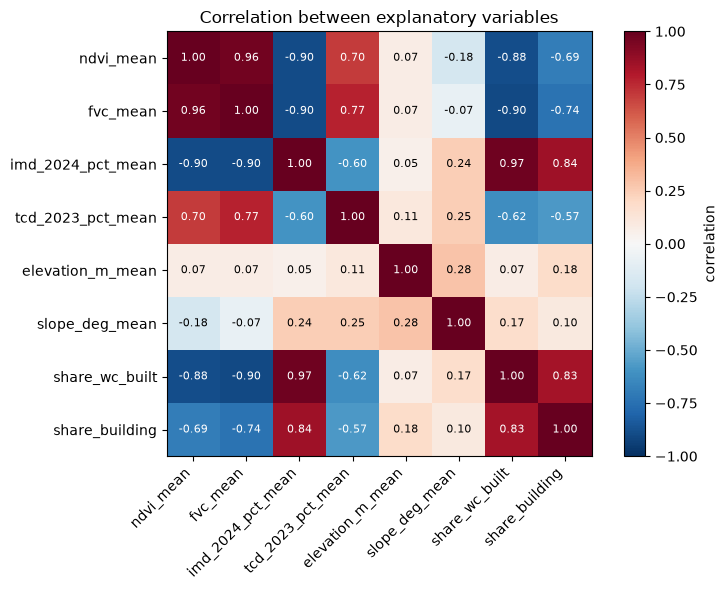

In [14]:
# correlation between the explanatory variables
corr = d[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)

# print the correlation value in each box
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(value) > 0.5 else 'black')

plt.colorbar(im, ax=ax, label='correlation')
ax.set_title('Correlation between explanatory variables')
plt.tight_layout()
plt.show()


### 7. Hypothesis test: is LST different in built-up and sparsely built cells?

We formulate a specific hypothesis and test it.
- **H0:** There is no difference in LST between cells with a high built-up share and cells with a low built-up share.
- **H1:** There is a difference.

LST is left-skewed and the two groups have different sizes, so we use a non-parametric test, the Mann–Whitney U test. It compares the ranks of the values rather than their means (Cox, 2017). We show the result as a boxplot rather than bars, because a bar chart with a truncated y-axis can exaggerate a difference.

The test assumes independent observations, but neighbouring cells are similar, so the p-value is optimistic. We treat it as a first indication, not as proof.

Built-up (>= 50 %): n = 710, median = 34.95 °C
Sparsely built (< 10 %): n = 179, median = 30.80 °C
Mann-Whitney U = 124328, p = 3.10e-87


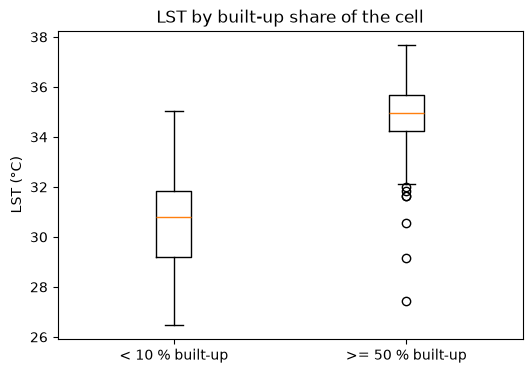

In [15]:
from scipy.stats import mannwhitneyu

built_high = d.loc[d['share_wc_built'] >= 0.5, 'lst_downscaled_C']
built_low = d.loc[d['share_wc_built'] < 0.1, 'lst_downscaled_C']

print(f'Built-up (>= 50 %): n = {len(built_high)}, median = {built_high.median():.2f} °C')
print(f'Sparsely built (< 10 %): n = {len(built_low)}, median = {built_low.median():.2f} °C')

u, p = mannwhitneyu(built_high, built_low, alternative='two-sided')
print(f'Mann-Whitney U = {u:.0f}, p = {p:.2e}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([built_low, built_high])
ax.set_xticks([1, 2])
ax.set_xticklabels(['< 10 % built-up', '>= 50 % built-up'])
ax.set_ylabel('LST (°C)')
ax.set_title('LST by built-up share of the cell')
plt.show()

### 8. What does this mean for the business question?

We translate the results into the terms of the business question, and we treat a null result as a result too. Before moving on to modelling, we answer the following in a markdown cell:

1. Which outliers did we find, and where are they? Are they errors or real physical features?
2. Which explanatory variables are clearly associated with LST, and are the relationships linear?
3. What does the test say about the difference between built-up and sparsely built areas? Can we reject H0?
4. What can we *not* conclude? Neighbouring cells are not independent, so the p-value is optimistic.
5. Which variables will we include in the model, and why? Should any be dropped because they are almost identical to another?

### World Cover 2021

Datasets/frames: 
- df = pixel id, longitute, latitude, x & y (figure out), built-up class code, elevation, slope  (10 m)
- wolrdcover_class = built-up classes & names (to be matched with world_cover_2021 class in df, in a new column)

**df**

In [16]:
df = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/3. WorldCover/worldcover_2021_elevation_slope_10m.csv')

In [17]:
df.head(10)

,pixel_id,lon,lat,x_utm,y_utm,worldcover_2021_class,elevation_m,slope_deg
0,717,12.565801,55.732706,347155.0,6179015.0,50,9.78,1.62
1,2482,12.565807,55.732616,347155.0,6179005.0,50,9.85,1.69
2,2483,12.565966,55.732619,347165.0,6179005.0,50,9.50,1.36
3,2484,12.566125,55.732622,347175.0,6179005.0,50,9.40,1.04
4,4247,12.565812,55.732526,347155.0,6178995.0,50,10.06,2.01
5,4248,12.565971,55.732529,347165.0,6178995.0,50,9.73,1.65
6,4249,12.566130,55.732533,347175.0,6178995.0,50,9.64,1.32
7,4250,12.566289,55.732536,347185.0,6178995.0,50,9.55,0.99
8,4251,12.566448,55.732539,347195.0,6178995.0,50,9.45,0.66
9,4252,12.566608,55.732542,347205.0,6178995.0,50,9.38,0.64


In [18]:
df.shape

(1030991, 8)

**worldcover_class**

In [19]:
worldcover_class = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/3. WorldCover/worldcover_2021_classes.csv')

In [20]:
# these encodings match the 2021 worldcover classes to the corresponding class names
worldcover_class.head(10)

,worldcover_2021_class,name
0,10,Tree cover
1,20,Shrubland
2,30,Grassland
3,40,Cropland
4,50,Built-up
5,60,Bare / sparse vegetation
6,70,Snow and ice
7,80,Permanent water bodies
8,90,Herbaceous wetland
9,95,Mangroves


In [21]:
worldcover_class.shape

(11, 2)

### Sentinel-2
- sentinel2 = ...
- scene_class = ...

In [22]:
sentinel2 =pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/1. Sentinel2/sentinel2_red_nir_ndvi_20230613_10m.csv')
sentinel2.head(10)

,pixel_id,lon,lat,x_utm,y_utm,s2_red_reflectance,s2_nir_reflectance,ndvi,fvc,s2_scl_class
0,717,12.565801,55.732706,347155.0,6179015.0,0.0794,0.1568,NaN,NaN,NaN
1,2482,12.565807,55.732616,347155.0,6179005.0,0.1228,0.2150,NaN,NaN,NaN
2,2483,12.565966,55.732619,347165.0,6179005.0,0.0732,0.2086,NaN,NaN,NaN
3,2484,12.566125,55.732622,347175.0,6179005.0,0.0658,0.1998,NaN,NaN,NaN
4,4247,12.565812,55.732526,347155.0,6178995.0,0.1512,0.1908,NaN,NaN,NaN
5,4248,12.565971,55.732529,347165.0,6178995.0,0.1318,0.2374,0.2860,0.0827,5.0
6,4249,12.566130,55.732533,347175.0,6178995.0,0.0672,0.2732,0.6052,0.4816,5.0
7,4250,12.566289,55.732536,347185.0,6178995.0,0.1078,0.1596,0.1937,0.0289,5.0
8,4251,12.566448,55.732539,347195.0,6178995.0,0.1022,0.1186,0.0743,0.0003,5.0
9,4252,12.566608,55.732542,347205.0,6178995.0,0.1084,0.1226,0.0615,0.0000,5.0


In [23]:
sentinel2.shape

(1030991, 10)

In [24]:
scene_class = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/1. Sentinel2/sentinel2_scene_classes.csv')

In [25]:
scene_class.head(10)

,s2_scl_class,name
0,0,No data
1,1,Saturated or defective
2,2,Dark area pixels
3,3,Cloud shadows
4,4,Vegetation
5,5,Not vegetated
6,6,Water
7,7,Unclassified
8,8,Cloud medium probability
9,9,Cloud high probability


In [26]:
scene_class.shape

(12, 2)

In [27]:
tcd = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/4. HRL Tree Cover Density/hrl_tcd2023_imd2021_imd2024_10m.csv')
tcd.head(10)

,pixel_id,lon,lat,x_utm,y_utm,tcd_2023_pct,imd_2021_pct,imd_2024_pct
0,717,12.565801,55.732706,347155.0,6179015.0,NaN,90.0,90.0
1,2482,12.565807,55.732616,347155.0,6179005.0,NaN,87.0,87.0
2,2483,12.565966,55.732619,347165.0,6179005.0,NaN,80.0,80.0
3,2484,12.566125,55.732622,347175.0,6179005.0,NaN,70.0,70.0
4,4247,12.565812,55.732526,347155.0,6178995.0,NaN,94.0,94.0
5,4248,12.565971,55.732529,347165.0,6178995.0,NaN,89.0,89.0
6,4249,12.566130,55.732533,347175.0,6178995.0,NaN,67.0,67.0
7,4250,12.566289,55.732536,347185.0,6178995.0,NaN,70.0,70.0
8,4251,12.566448,55.732539,347195.0,6178995.0,NaN,95.0,95.0
9,4252,12.566608,55.732542,347205.0,6178995.0,NaN,100.0,100.0


In [28]:
tcd.shape

(1030991, 8)

In [29]:
urban_atlas = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/5. Urban Atlas/urban_atlas_2021_10m.csv')
urban_atlas.head(10)

,pixel_id,lon,lat,x_utm,y_utm,ua_lclu_2021_code,ua_bbh_2021_m,ua_street_tree_2021
0,717,12.565801,55.732706,347155.0,6179015.0,11100.0,NaN,0
1,2482,12.565807,55.732616,347155.0,6179005.0,11100.0,NaN,1
2,2483,12.565966,55.732619,347165.0,6179005.0,11100.0,NaN,1
3,2484,12.566125,55.732622,347175.0,6179005.0,12230.0,NaN,1
4,4247,12.565812,55.732526,347155.0,6178995.0,11100.0,NaN,0
5,4248,12.565971,55.732529,347165.0,6178995.0,11100.0,NaN,0
6,4249,12.566130,55.732533,347175.0,6178995.0,12230.0,NaN,1
7,4250,12.566289,55.732536,347185.0,6178995.0,12230.0,NaN,1
8,4251,12.566448,55.732539,347195.0,6178995.0,12230.0,NaN,0
9,4252,12.566608,55.732542,347205.0,6178995.0,12230.0,NaN,0


In [30]:
urban_atlas.shape

(1030991, 8)

In [31]:
urban_atlas_class

NameError: name 'urban_atlas_class' is not defined

### CLIM4Cities - the dependent variable/outcome variable

In [ ]:
lst_2023 = pd.read_csv('/Users/isabellekroejgaard/Documents/ITU2026/Project 2.0/Data/2. CLIM4Cities/lst_clim4cities_20230613_10m.csv') 
lst_2023.head(10)

,pixel_id,lon,lat,x_utm,y_utm,lst_downscaled_K,lst_downscaled_C,lst_interpolated_K,lst_cell_id
0,717,12.565801,55.732706,347155.0,6179015.0,307.29,34.14,306.51,36.0
1,2482,12.565807,55.732616,347155.0,6179005.0,307.29,34.14,306.51,36.0
2,2483,12.565966,55.732619,347165.0,6179005.0,307.29,34.14,306.51,36.0
3,2484,12.566125,55.732622,347175.0,6179005.0,307.29,34.14,306.51,36.0
4,4247,12.565812,55.732526,347155.0,6178995.0,307.98,34.83,306.55,111.0
5,4248,12.565971,55.732529,347165.0,6178995.0,307.98,34.83,306.55,111.0
6,4249,12.566130,55.732533,347175.0,6178995.0,307.98,34.83,306.55,111.0
7,4250,12.566289,55.732536,347185.0,6178995.0,307.98,34.83,306.55,111.0
8,4251,12.566448,55.732539,347195.0,6178995.0,307.14,33.99,306.03,112.0
9,4252,12.566608,55.732542,347205.0,6178995.0,307.14,33.99,306.03,112.0


In [ ]:
lst_2023.tail(10)

,pixel_id,lon,lat,x_utm,y_utm,lst_downscaled_K,lst_downscaled_C,lst_interpolated_K,lst_cell_id
1030981,2326564,12.506047,55.613038,342925.0,6165835.0,NaN,NaN,NaN,2868.0
1030982,2326583,12.509061,55.613099,343115.0,6165835.0,NaN,NaN,NaN,2869.0
1030983,2326584,12.509219,55.613103,343125.0,6165835.0,NaN,NaN,NaN,2869.0
1030984,2326585,12.509378,55.613106,343135.0,6165835.0,NaN,NaN,NaN,2869.0
1030985,2326628,12.516198,55.613244,343565.0,6165835.0,NaN,NaN,NaN,2871.0
1030986,2328348,12.509066,55.613010,343115.0,6165825.0,NaN,NaN,NaN,2869.0
1030987,2328349,12.509225,55.613013,343125.0,6165825.0,NaN,NaN,NaN,2869.0
1030988,2330157,12.516051,55.613061,343555.0,6165815.0,NaN,NaN,NaN,2871.0
1030989,2331922,12.516056,55.612972,343555.0,6165805.0,NaN,NaN,NaN,2871.0
1030990,2333687,12.516062,55.612882,343555.0,6165795.0,NaN,NaN,NaN,2871.0


### Machine learning: predicting LST (df_master)

In [ ]:
# keep only cells with an LST value (water and coast cells have none)
ml = df_master.dropna(subset=['lst_downscaled_C']).copy()

# features: cell averages of the 10 m data (LST columns are left out, they would give away the answer)
features = ['ndvi_mean', 'fvc_mean', 'imd_2021_pct_mean', 'imd_2024_pct_mean', 'tcd_2023_pct_mean',
            'elevation_m_mean', 'slope_deg_mean', 'share_wc_tree', 'share_wc_grass', 'share_wc_built',
            'share_wc_water', 'share_ua_street_tree', 'share_building', 'bbh_mean_where_built_m']

# no buildings in the cell means building height is 0
ml['bbh_mean_where_built_m'] = ml['bbh_mean_where_built_m'].fillna(0)

# drop the few cells that are still missing a feature
ml = ml.dropna(subset=features)
print(ml.shape)

(1159, 21)


**Spatial split**: the easternmost 20% of cells are the test set, so the model is tested on a different area than it was trained on

In [ ]:
cut = ml['lst_cell_lon'].quantile(0.8)
train = ml[ml['lst_cell_lon'] < cut]
test = ml[ml['lst_cell_lon'] >= cut]
print(len(train), len(test))

918 241


**Model**: random forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
model.fit(train[features], train['lst_downscaled_C'])
pred = model.predict(test[features])

print('MAE (°C):', mean_absolute_error(test['lst_downscaled_C'], pred))
print('R2:', r2_score(test['lst_downscaled_C'], pred))

MAE (°C): 0.6727449515905868
R2: 0.8035312569854338


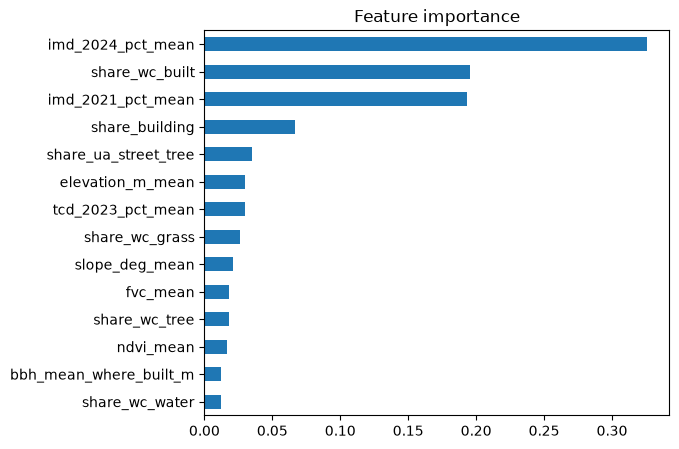

In [ ]:
importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot(kind='barh', figsize=(6, 5))
plt.title('Feature importance')
plt.show()